# Neural Networks — Haberman's Survival Dataset

**University Project (2022)**

This notebook is a cleaned and documented version of the original university implementation.  
It keeps the original methodology and technologies while correcting issues that prevented a reproducible execution.

### Main topics
- Dataset exploration and preprocessing
- Feed-forward neural network classification with **Neurolab**
- Architecture / training-parameter experiments
- Different train/test split experiments
- Elbow method and silhouette score
- Competitive / Kohonen-style learning with WTA and CWTA


## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import neurolab as nl

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, silhouette_score
from yellowbrick.cluster import KElbowVisualizer

import time

start_time = time.time()

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 2. Dataset Loading

The project uses **Haberman's Survival Dataset**.

The dataset contains 306 patient records and three input features:

1. Age of the patient at the time of operation
2. Year of operation
3. Number of positive axillary nodes detected

The target variable is the survival status:

- `1` → patient survived 5 years or longer
- `2` → patient died within 5 years


In [2]:
# The notebook is expected to be stored in:
# neural-networks-haberman-survival/notebooks/
# and the dataset in:
# neural-networks-haberman-survival/data/

possible_paths = [
    Path("../data/haberman.data"),
    Path("data/haberman.data"),
    Path("haberman.data"),
]

data_path = next((p for p in possible_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "haberman.data was not found. Place it inside the project's data/ folder."
    )

column_names = [
    "age",
    "operation_year",
    "positive_axillary_nodes",
    "survival_status",
]

data = pd.read_csv(data_path, header=None, names=column_names)

print(f"Dataset path: {data_path}")
print(f"Dataset shape: {data.shape}")
display(data.head())


Dataset path: ..\data\haberman.data
Dataset shape: (306, 4)


,age,operation_year,positive_axillary_nodes,survival_status
0,30,64,1,1
1,30,62,3,1
2,30,65,0,1
3,31,59,2,1
4,31,65,4,1


## 3. Dataset Exploration

In [3]:
print("Dataset information:")
data.info()

print("\nClass distribution:")
print(data["survival_status"].value_counts().sort_index())

print("\nMissing values:")
print(data.isnull().sum())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   age                      306 non-null    int64
 1   operation_year           306 non-null    int64
 2   positive_axillary_nodes  306 non-null    int64
 3   survival_status          306 non-null    int64
dtypes: int64(4)
memory usage: 9.7 KB

Class distribution:
survival_status
1    225
2     81
Name: count, dtype: int64

Missing values:
age                        0
operation_year             0
positive_axillary_nodes    0
survival_status            0
dtype: int64


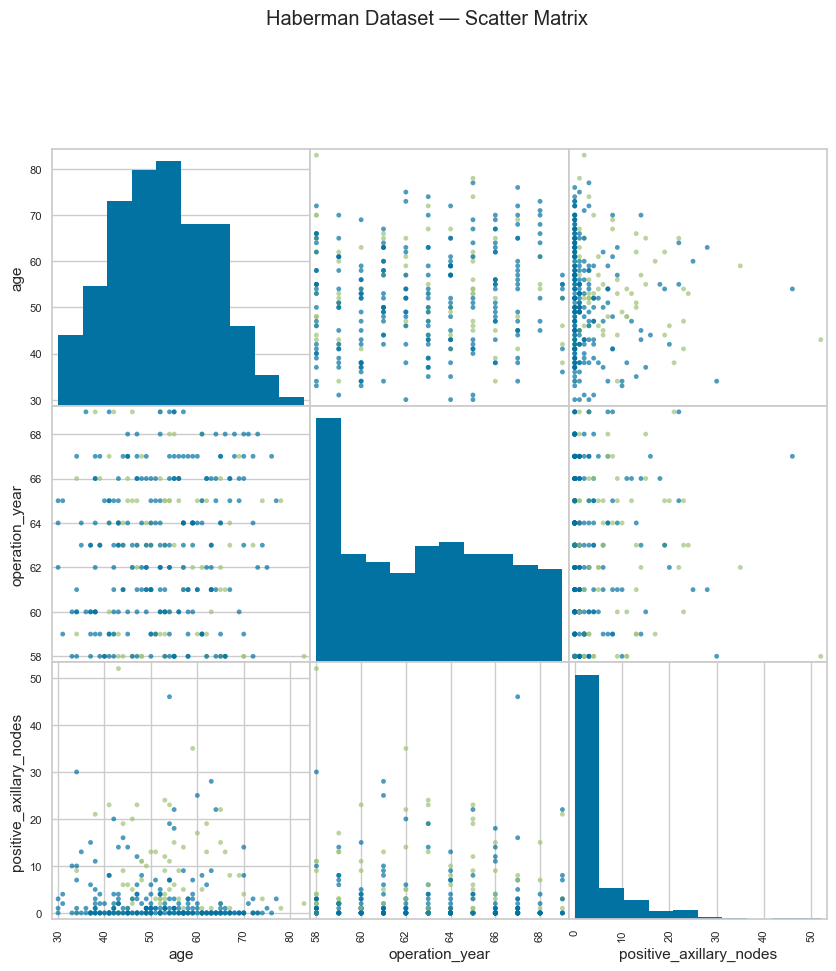

In [4]:
# Scatter matrix of the three features.
# Colors correspond to the original survival class.

class_colors = data["survival_status"].map({1: "C0", 2: "C1"})

pd.plotting.scatter_matrix(
    data[["age", "operation_year", "positive_axillary_nodes"]],
    figsize=(10, 10),
    diagonal="hist",
    c=class_colors,
    alpha=0.7,
)

plt.suptitle("Haberman Dataset — Scatter Matrix", y=1.02)
plt.show()


## 4. Missing Values and Outliers

The dataset documentation states that there are no missing values.  
The check above verifies this directly in the loaded data.

For this cleaned version, no samples are removed automatically as outliers.  
The original university project focused primarily on neural-network training and comparison of network configurations.


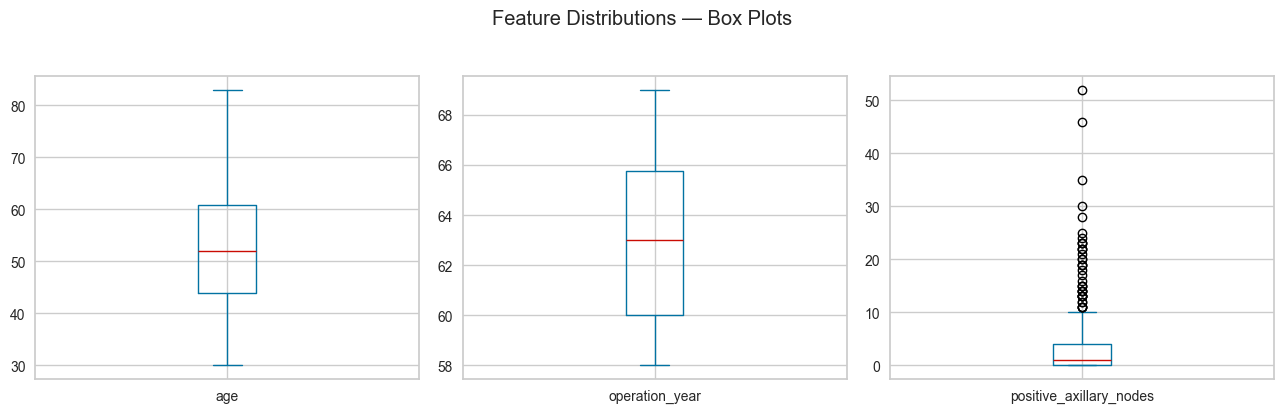

In [5]:
# Box plots for a visual inspection of the three input features.

data[["age", "operation_year", "positive_axillary_nodes"]].plot(
    kind="box",
    subplots=True,
    layout=(1, 3),
    figsize=(13, 4),
    sharex=False,
    sharey=False,
)

plt.suptitle("Feature Distributions — Box Plots", y=1.03)
plt.tight_layout()
plt.show()


## 5. Feature / Target Preparation

The original project manually constructed the target matrix using row ranges.  
Here the target is derived directly from the actual `survival_status` column.

For Neurolab, the two classes are represented with two output neurons:

- Class `1` → `[1, 0]`
- Class `2` → `[0, 1]`


In [6]:
X = data[["age", "operation_year", "positive_axillary_nodes"]].to_numpy(dtype=float)
y = data["survival_status"].to_numpy(dtype=int)

# One-hot target for the two output neurons.
T = np.zeros((len(y), 2), dtype=float)
T[y == 1] = [1.0, 0.0]
T[y == 2] = [0.0, 1.0]

print("X shape:", X.shape)
print("T shape:", T.shape)
print("First five targets:")
print(T[:5])


X shape: (306, 3)
T shape: (306, 2)
First five targets:
[[1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]]


## 6. Initial 70% / 30% Train-Test Split and Scaling

In [7]:
X_train, X_test, T_train, T_test, y_train, y_test = train_test_split(
    X,
    T,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train_scaled))
print("Test samples:", len(X_test_scaled))


Training samples: 214
Test samples: 92


## 7. Feed-Forward Neural Network

The initial architecture follows the same style as the original implementation:

- 3 input features
- 1 hidden layer with 5 neurons
- 2 output neurons
- Logistic sigmoid activation
- Resilient backpropagation (`train_rprop`)
- Learning rate: `0.3`
- Maximum epochs: `3000`
- Performance goal: `1e-5`
- Display interval: `100`


In [8]:
def create_feedforward_network(hidden_neurons, seed=RANDOM_STATE):
    np.random.seed(seed)

    # Inputs are scaled to [0, 1].
    net = nl.net.newff([[0.0, 1.0]] * X_train_scaled.shape[1],
                       [hidden_neurons, 2])

    net.layers[0].transf = nl.trans.LogSig()
    net.layers[1].transf = nl.trans.LogSig()

    return net


def train_and_evaluate(
    hidden_neurons,
    learning_rate,
    epochs,
    X_train_data,
    T_train_data,
    X_test_data,
    y_test_data,
    seed=RANDOM_STATE,
    show=100,
    goal=1e-5,
):
    net = create_feedforward_network(hidden_neurons, seed=seed)

    error = nl.train.train_rprop(
        net,
        X_train_data,
        T_train_data,
        epochs=epochs,
        show=show,
        goal=goal,
        lr=learning_rate,
    )

    output = net.sim(X_test_data)
    predicted_class = np.argmax(output, axis=1) + 1
    accuracy = accuracy_score(y_test_data, predicted_class)

    return net, error, predicted_class, accuracy


In [9]:
initial_net, initial_error, initial_predictions, initial_accuracy = train_and_evaluate(
    hidden_neurons=5,
    learning_rate=0.3,
    epochs=3000,
    X_train_data=X_train_scaled,
    T_train_data=T_train,
    X_test_data=X_test_scaled,
    y_test_data=y_test,
)

print(f"Initial 70/30 test accuracy: {initial_accuracy:.4f}")


c:\Users\arion\anaconda3\envs\cv\lib\site-packages\neurolab\trans.py:107: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))


Epoch: 100; Error: 30.363111479666003;
Epoch: 200; Error: 28.86999541293259;
Epoch: 300; Error: 27.713003685042466;
Epoch: 400; Error: 27.269000919309335;
Epoch: 500; Error: 26.797344644015112;
Epoch: 600; Error: 26.438374359469577;
Epoch: 700; Error: 26.16883452396314;
Epoch: 800; Error: 25.98535134129531;
Epoch: 900; Error: 25.80861796488451;
Epoch: 1000; Error: 25.675600116795387;
Epoch: 1100; Error: 25.577740983430353;
Epoch: 1200; Error: 25.492754562924556;
Epoch: 1300; Error: 25.409814362312524;
Epoch: 1400; Error: 25.346585116205624;
Epoch: 1500; Error: 25.29748770806074;
Epoch: 1600; Error: 25.242352641005347;
Epoch: 1700; Error: 25.200036602961017;
Epoch: 1800; Error: 25.16342554437899;
Epoch: 1900; Error: 25.129939750403878;
Epoch: 2000; Error: 25.095625285242928;
Epoch: 2100; Error: 25.05877988016696;
Epoch: 2200; Error: 25.029743773259234;
Epoch: 2300; Error: 24.99512578648529;
Epoch: 2400; Error: 24.959957985859177;
Epoch: 2500; Error: 24.932413646475766;
Epoch: 2600; Erro

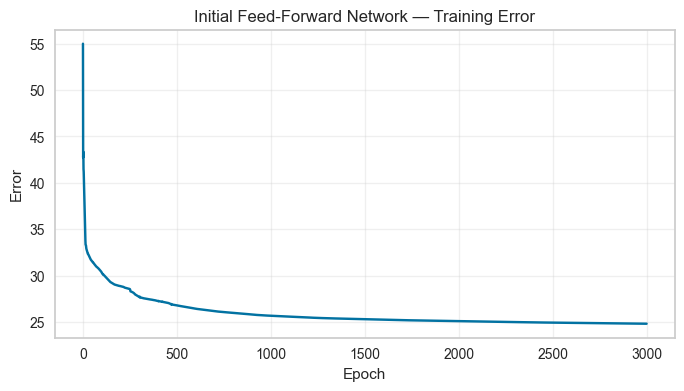

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(initial_error)
plt.title("Initial Feed-Forward Network — Training Error")
plt.xlabel("Epoch")
plt.ylabel("Error")
plt.grid(alpha=0.3)
plt.show()


## 8. Test-Set Classification

In [11]:
comparison = pd.DataFrame({
    "actual_class": y_test,
    "predicted_class": initial_predictions,
})

display(comparison.head(20))
print(f"Accuracy: {initial_accuracy:.2%}")


,actual_class,predicted_class
0,1,1
1,1,1
2,2,1
3,1,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


Accuracy: 71.74%


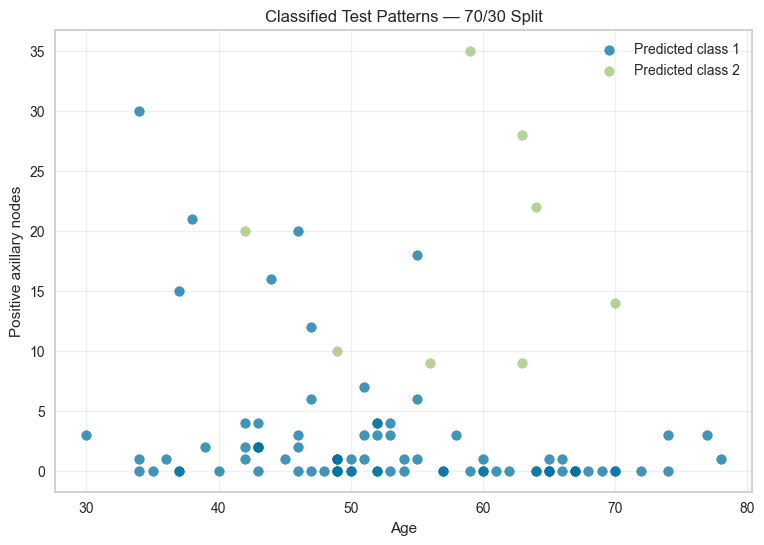

In [12]:
plt.figure(figsize=(9, 6))

for predicted_class in [1, 2]:
    mask = initial_predictions == predicted_class
    plt.scatter(
        X_test[mask, 0],
        X_test[mask, 2],
        label=f"Predicted class {predicted_class}",
        alpha=0.75,
    )

plt.xlabel("Age")
plt.ylabel("Positive axillary nodes")
plt.title("Classified Test Patterns — 70/30 Split")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 9. Architecture / Training-Parameter Experiments

The following configurations preserve the type of experiments performed in the original project:  
changing the number of hidden neurons, learning rate, and number of epochs.

Each experiment starts with a **new neural network**, so the results are independent.


In [13]:
experiment_configs = [
    {"name": "Initial",  "hidden_neurons": 5,  "learning_rate": 0.3, "epochs": 3000},
    {"name": "Change 1", "hidden_neurons": 10, "learning_rate": 0.3, "epochs": 3000},
    {"name": "Change 2", "hidden_neurons": 8,  "learning_rate": 0.5, "epochs": 3000},
    {"name": "Change 3", "hidden_neurons": 10, "learning_rate": 0.2, "epochs": 5000},
]

experiment_results = []
experiment_errors = {}

for i, config in enumerate(experiment_configs):
    net, error, predictions, accuracy = train_and_evaluate(
        hidden_neurons=config["hidden_neurons"],
        learning_rate=config["learning_rate"],
        epochs=config["epochs"],
        X_train_data=X_train_scaled,
        T_train_data=T_train,
        X_test_data=X_test_scaled,
        y_test_data=y_test,
        seed=RANDOM_STATE + i,
        show=100,
    )

    experiment_errors[config["name"]] = error

    experiment_results.append({
        "experiment": config["name"],
        "hidden_neurons": config["hidden_neurons"],
        "learning_rate": config["learning_rate"],
        "epochs": config["epochs"],
        "final_training_error": error[-1] if len(error) else np.nan,
        "test_accuracy": accuracy,
    })

experiment_results_df = pd.DataFrame(experiment_results)
display(experiment_results_df)


c:\Users\arion\anaconda3\envs\cv\lib\site-packages\neurolab\trans.py:107: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))


Epoch: 100; Error: 30.363111479666003;
Epoch: 200; Error: 28.86999541293259;
Epoch: 300; Error: 27.713003685042466;
Epoch: 400; Error: 27.269000919309335;
Epoch: 500; Error: 26.797344644015112;
Epoch: 600; Error: 26.438374359469577;
Epoch: 700; Error: 26.16883452396314;
Epoch: 800; Error: 25.98535134129531;
Epoch: 900; Error: 25.80861796488451;
Epoch: 1000; Error: 25.675600116795387;
Epoch: 1100; Error: 25.577740983430353;
Epoch: 1200; Error: 25.492754562924556;
Epoch: 1300; Error: 25.409814362312524;
Epoch: 1400; Error: 25.346585116205624;
Epoch: 1500; Error: 25.29748770806074;
Epoch: 1600; Error: 25.242352641005347;
Epoch: 1700; Error: 25.200036602961017;
Epoch: 1800; Error: 25.16342554437899;
Epoch: 1900; Error: 25.129939750403878;
Epoch: 2000; Error: 25.095625285242928;
Epoch: 2100; Error: 25.05877988016696;
Epoch: 2200; Error: 25.029743773259234;
Epoch: 2300; Error: 24.99512578648529;
Epoch: 2400; Error: 24.959957985859177;
Epoch: 2500; Error: 24.932413646475766;
Epoch: 2600; Erro

c:\Users\arion\anaconda3\envs\cv\lib\site-packages\neurolab\trans.py:107: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))


Epoch: 100; Error: 26.892653261060573;
Epoch: 200; Error: 24.53595298840073;
Epoch: 300; Error: 22.818976476423146;
Epoch: 400; Error: 21.974833146983286;
Epoch: 500; Error: 21.252723010117684;
Epoch: 600; Error: 20.837713162163517;
Epoch: 700; Error: 20.45943200959454;
Epoch: 800; Error: 20.234311434957828;
Epoch: 900; Error: 20.03548297269023;
Epoch: 1000; Error: 19.835902915756844;
Epoch: 1100; Error: 19.68660814142796;
Epoch: 1200; Error: 19.547931513208436;
Epoch: 1300; Error: 19.423936343660593;
Epoch: 1400; Error: 19.29793566781766;
Epoch: 1500; Error: 19.17087519002127;
Epoch: 1600; Error: 19.03106292353416;
Epoch: 1700; Error: 18.861732569415018;
Epoch: 1800; Error: 18.676206115392844;
Epoch: 1900; Error: 18.437415520832587;
Epoch: 2000; Error: 17.740211151832323;
Epoch: 2100; Error: 17.42450998274848;
Epoch: 2200; Error: 17.24691758913038;
Epoch: 2300; Error: 17.012953068293513;
Epoch: 2400; Error: 16.727200365212134;
Epoch: 2500; Error: 16.47126255210826;
Epoch: 2600; Error:

,experiment,hidden_neurons,learning_rate,epochs,final_training_error,test_accuracy
0,Initial,5,0.3,3000,24.816795,0.717391
1,Change 1,10,0.3,3000,15.847334,0.619565
2,Change 2,8,0.5,3000,18.575663,0.706522
3,Change 3,10,0.2,5000,16.490072,0.619565


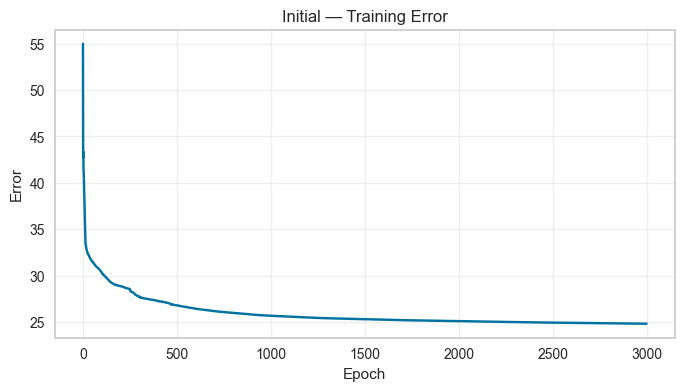

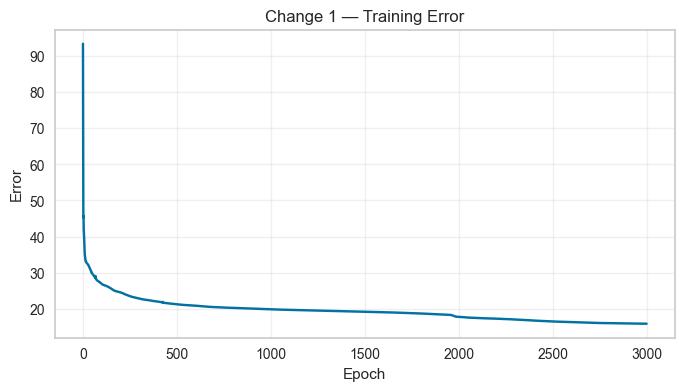

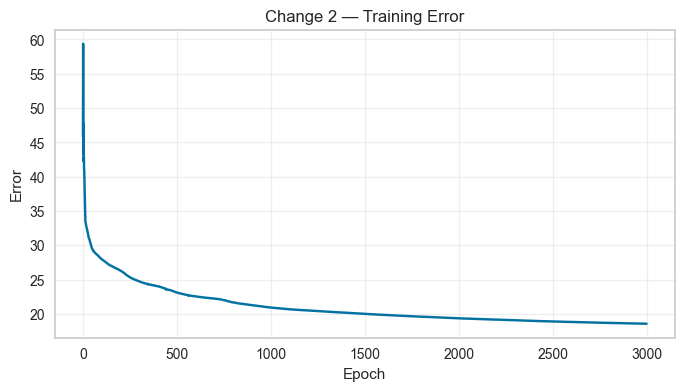

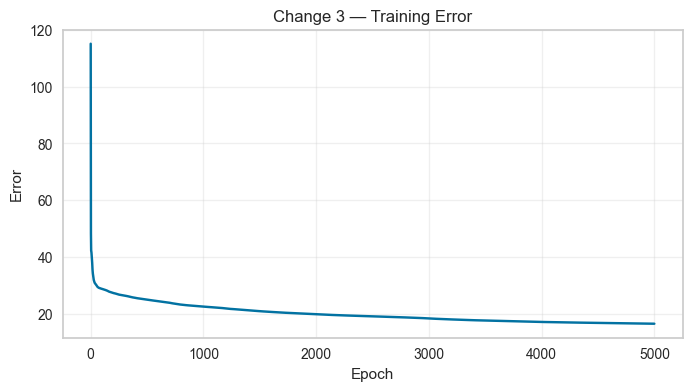

In [14]:
for name, error in experiment_errors.items():
    plt.figure(figsize=(8, 4))
    plt.plot(error)
    plt.title(f"{name} — Training Error")
    plt.xlabel("Epoch")
    plt.ylabel("Error")
    plt.grid(alpha=0.3)
    plt.show()


In [15]:
best_row = experiment_results_df.loc[
    experiment_results_df["test_accuracy"].idxmax()
]

best_config = {
    "hidden_neurons": int(best_row["hidden_neurons"]),
    "learning_rate": float(best_row["learning_rate"]),
    "epochs": int(best_row["epochs"]),
}

print("Best configuration from the 70/30 experiments:")
print(best_config)
print(f"Accuracy: {best_row['test_accuracy']:.4f}")


Best configuration from the 70/30 experiments:
{'hidden_neurons': 5, 'learning_rate': 0.3, 'epochs': 3000}
Accuracy: 0.7174


## 10. Different Train/Test Split Experiments

The best configuration from the previous section is retrained independently using:

- 50% / 50%
- 60% / 40%
- 70% / 30%
- 80% / 20%
- 90% / 10%

For every split:
1. A new training/test partition is created.
2. The scaler is fitted only on the training set.
3. A new neural network is created and trained.
4. Accuracy is measured only on the corresponding test set.


In [16]:
split_experiments = [
    ("50/50", 0.50),
    ("60/40", 0.40),
    ("70/30", 0.30),
    ("80/20", 0.20),
    ("90/10", 0.10),
]

split_results = []

for i, (split_name, test_size) in enumerate(split_experiments):
    X_tr, X_te, T_tr, T_te, y_tr, y_te = train_test_split(
        X,
        T,
        y,
        test_size=test_size,
        random_state=RANDOM_STATE,
        stratify=y,
    )

    split_scaler = MinMaxScaler()
    X_tr_scaled = split_scaler.fit_transform(X_tr)
    X_te_scaled = split_scaler.transform(X_te)

    net, error, predictions, accuracy = train_and_evaluate(
        hidden_neurons=best_config["hidden_neurons"],
        learning_rate=best_config["learning_rate"],
        epochs=best_config["epochs"],
        X_train_data=X_tr_scaled,
        T_train_data=T_tr,
        X_test_data=X_te_scaled,
        y_test_data=y_te,
        seed=RANDOM_STATE + 100 + i,
        show=100,
    )

    split_results.append({
        "split": split_name,
        "training_samples": len(X_tr),
        "test_samples": len(X_te),
        "final_training_error": error[-1] if len(error) else np.nan,
        "test_accuracy": accuracy,
    })

split_results_df = pd.DataFrame(split_results)
display(split_results_df)


c:\Users\arion\anaconda3\envs\cv\lib\site-packages\neurolab\trans.py:107: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))


Epoch: 100; Error: 16.677529045201318;
Epoch: 200; Error: 15.755590358819603;
Epoch: 300; Error: 15.431703818605728;
Epoch: 400; Error: 15.196210719157177;
Epoch: 500; Error: 15.012258317321201;
Epoch: 600; Error: 14.891676239624775;
Epoch: 700; Error: 14.797580982057912;
Epoch: 800; Error: 14.736318806762851;
Epoch: 900; Error: 14.676631394326677;
Epoch: 1000; Error: 14.631961271279252;
Epoch: 1100; Error: 14.60141994286862;
Epoch: 1200; Error: 14.570430118671322;
Epoch: 1300; Error: 14.544233230039215;
Epoch: 1400; Error: 14.51543903256393;
Epoch: 1500; Error: 14.490113661930685;
Epoch: 1600; Error: 14.465598086273758;
Epoch: 1700; Error: 14.44677640638174;
Epoch: 1800; Error: 14.427083461771213;
Epoch: 1900; Error: 14.409051136942766;
Epoch: 2000; Error: 14.393307855268905;
Epoch: 2100; Error: 14.378724633908828;
Epoch: 2200; Error: 14.364404512790978;
Epoch: 2300; Error: 14.351026585245553;
Epoch: 2400; Error: 14.339835853432678;
Epoch: 2500; Error: 14.328519833447908;
Epoch: 2600;

c:\Users\arion\anaconda3\envs\cv\lib\site-packages\neurolab\trans.py:107: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))


Epoch: 200; Error: 29.137016079174686;
Epoch: 300; Error: 28.414723473741873;
Epoch: 400; Error: 27.732904153839634;
Epoch: 500; Error: 27.194079231990408;
Epoch: 600; Error: 26.93767897381146;
Epoch: 700; Error: 26.68720543966401;
Epoch: 800; Error: 26.416713633467516;
Epoch: 900; Error: 26.133325350638355;
Epoch: 1000; Error: 25.897211019582194;
Epoch: 1100; Error: 25.706089385358844;
Epoch: 1200; Error: 25.555417533384375;
Epoch: 1300; Error: 25.416890908955757;
Epoch: 1400; Error: 25.305279211885576;
Epoch: 1500; Error: 25.216270510004446;
Epoch: 1600; Error: 25.138087339493218;
Epoch: 1700; Error: 25.06491981947334;
Epoch: 1800; Error: 25.000794974212443;
Epoch: 1900; Error: 24.942037486842008;
Epoch: 2000; Error: 24.88262596189645;
Epoch: 2100; Error: 24.82478952677494;
Epoch: 2200; Error: 24.770767664016063;
Epoch: 2300; Error: 24.721737150142626;
Epoch: 2400; Error: 24.67700734456467;
Epoch: 2500; Error: 24.6314395987635;
Epoch: 2600; Error: 24.59003222074434;
Epoch: 2700; Erro

c:\Users\arion\anaconda3\envs\cv\lib\site-packages\neurolab\trans.py:107: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))


Epoch: 1400; Error: 35.03560158903137;
Epoch: 1500; Error: 34.96693562015744;
Epoch: 1600; Error: 34.898612887249385;
Epoch: 1700; Error: 34.83632144117082;
Epoch: 1800; Error: 34.7794358072566;
Epoch: 1900; Error: 34.725104419326584;
Epoch: 2000; Error: 34.67197049808662;
Epoch: 2100; Error: 34.62169889859777;
Epoch: 2200; Error: 34.57583811061965;
Epoch: 2300; Error: 34.52965188062201;
Epoch: 2400; Error: 34.48768452325412;
Epoch: 2500; Error: 34.44865308202274;
Epoch: 2600; Error: 34.415407701789704;
Epoch: 2700; Error: 34.38492459234307;
Epoch: 2800; Error: 34.3548723249296;
Epoch: 2900; Error: 34.32787878420413;
Epoch: 3000; Error: 34.29920526722232;
The maximum number of train epochs is reached


,split,training_samples,test_samples,final_training_error,test_accuracy
0,50/50,153,153,14.284279,0.620915
1,60/40,183,123,19.072383,0.674797
2,70/30,214,92,24.432792,0.619565
3,80/20,244,62,32.247200,0.612903
4,90/10,275,31,34.299205,0.645161


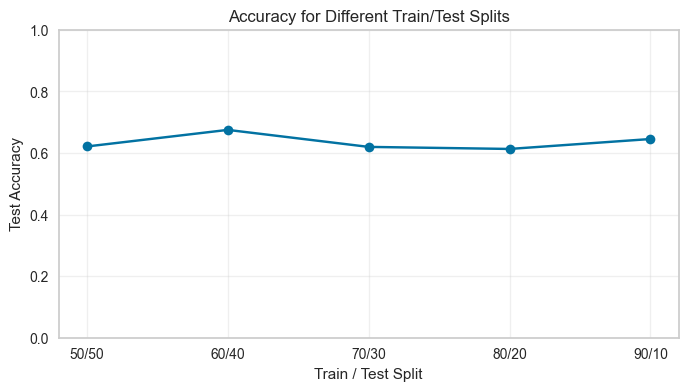

In [17]:
plt.figure(figsize=(8, 4))
plt.plot(
    split_results_df["split"],
    split_results_df["test_accuracy"],
    marker="o",
)
plt.ylim(0, 1)
plt.xlabel("Train / Test Split")
plt.ylabel("Test Accuracy")
plt.title("Accuracy for Different Train/Test Splits")
plt.grid(alpha=0.3)
plt.show()


## 11. Unsupervised Learning — Cluster Selection

For unsupervised learning, the class column is **not used**.  
Only the three input features are included.

The number of clusters is investigated using:

- Silhouette score
- Elbow method


In [18]:
unsupervised_scaler = MinMaxScaler()
X_unsupervised = unsupervised_scaler.fit_transform(X)

silhouette_results = []

for k in range(2, 8):
    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10,
    )
    labels = kmeans.fit_predict(X_unsupervised)
    score = silhouette_score(X_unsupervised, labels)
    silhouette_results.append((k, score))

silhouette_df = pd.DataFrame(
    silhouette_results,
    columns=["clusters", "silhouette_score"],
)

display(silhouette_df)


c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known

,clusters,silhouette_score
0,2,0.386881
1,3,0.334772
2,4,0.291146
3,5,0.309586
4,6,0.312758
5,7,0.307924


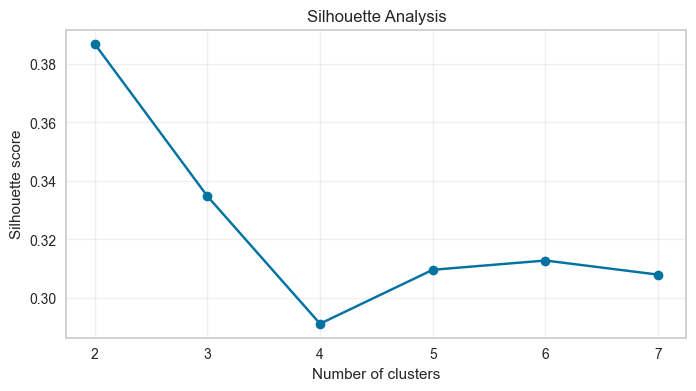

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(
    silhouette_df["clusters"],
    silhouette_df["silhouette_score"],
    marker="o",
)
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("Silhouette Analysis")
plt.grid(alpha=0.3)
plt.show()


c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known

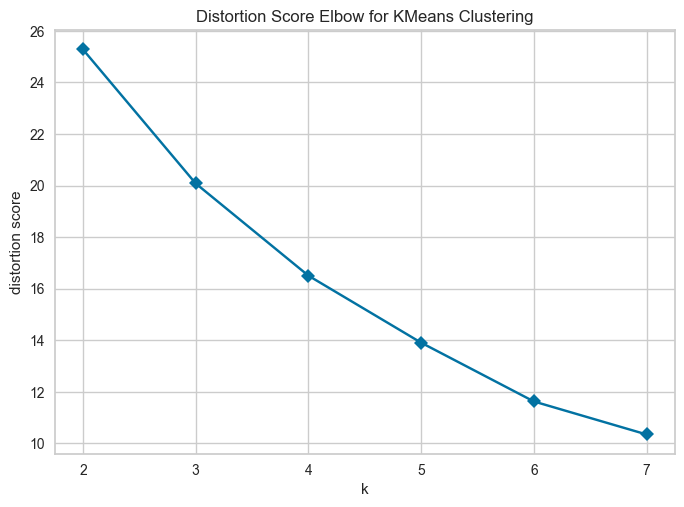

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [20]:
model = KMeans(random_state=RANDOM_STATE, n_init=10)

visualizer = KElbowVisualizer(
    model,
    k=(2, 8),
    timings=False,
)

visualizer.fit(X_unsupervised)
visualizer.show()


In [21]:
best_k = int(
    silhouette_df.loc[
        silhouette_df["silhouette_score"].idxmax(),
        "clusters"
    ]
)

print("Best number of clusters according to silhouette score:", best_k)


Best number of clusters according to silhouette score: 2


## 12. Competitive / Kohonen-Style Network

A competitive network is trained using the normalized input features only.

Two training algorithms are compared:

- Winner-Take-All (WTA)
- Conscience Winner-Take-All (CWTA)

The number of competitive neurons is set to the selected number of clusters.


Epoch: 100; Error: 123.26731669459389;
Epoch: 200; Error: 123.26731669459389;
Epoch: 300; Error: 123.26731669459389;
Epoch: 400; Error: 123.26731669459389;
Epoch: 500; Error: 123.26731669459389;
Epoch: 600; Error: 123.26731669459389;
Epoch: 700; Error: 123.26731669459389;
Epoch: 800; Error: 123.26731669459389;
Epoch: 900; Error: 123.26731669459389;
Epoch: 1000; Error: 123.26731669459389;
Epoch: 1100; Error: 123.26731669459389;
Epoch: 1200; Error: 123.26731669459389;
Epoch: 1300; Error: 123.26731669459389;
Epoch: 1400; Error: 123.26731669459389;
Epoch: 1500; Error: 123.26731669459389;
Epoch: 1600; Error: 123.26731669459389;
Epoch: 1700; Error: 123.26731669459389;
Epoch: 1800; Error: 123.26731669459389;
Epoch: 1900; Error: 123.26731669459389;
Epoch: 2000; Error: 123.26731669459389;
Epoch: 2100; Error: 123.26731669459389;
Epoch: 2200; Error: 123.26731669459389;
Epoch: 2300; Error: 123.26731669459389;
Epoch: 2400; Error: 123.26731669459389;
Epoch: 2500; Error: 123.26731669459389;
Epoch: 26

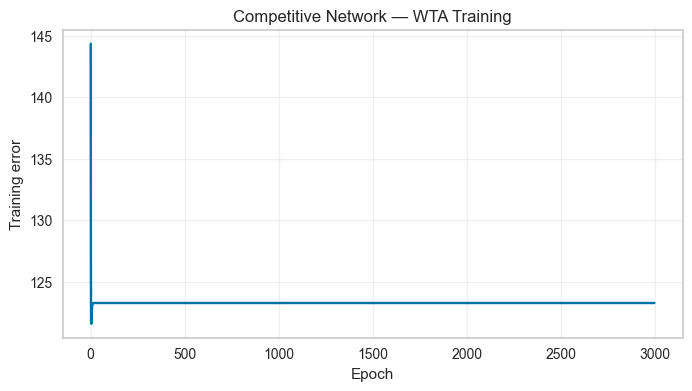

In [22]:
np.random.seed(RANDOM_STATE)

net_wta = nl.net.newc(
    [[0.0, 1.0]] * X_unsupervised.shape[1],
    best_k,
)

error_wta = nl.train.train_wta(
    net_wta,
    X_unsupervised,
    epochs=3000,
    show=100,
)

plt.figure(figsize=(8, 4))
plt.plot(error_wta)
plt.xlabel("Epoch")
plt.ylabel("Training error")
plt.title("Competitive Network — WTA Training")
plt.grid(alpha=0.3)
plt.show()


Epoch: 100; Error: 123.14898656126951;
Epoch: 200; Error: 123.14898656126951;
Epoch: 300; Error: 123.14898656126951;
Epoch: 400; Error: 123.14898656126951;
Epoch: 500; Error: 123.14898656126951;
Epoch: 600; Error: 123.14898656126951;
Epoch: 700; Error: 123.14898656126951;
Epoch: 800; Error: 123.14898656126951;
Epoch: 900; Error: 123.14898656126951;
Epoch: 1000; Error: 123.14898656126951;
Epoch: 1100; Error: 123.14898656126951;
Epoch: 1200; Error: 123.14898656126951;
Epoch: 1300; Error: 123.14898656126951;
Epoch: 1400; Error: 123.14898656126951;
Epoch: 1500; Error: 123.14898656126951;
Epoch: 1600; Error: 123.14898656126951;
Epoch: 1700; Error: 123.14898656126951;
Epoch: 1800; Error: 123.14898656126951;
Epoch: 1900; Error: 123.14898656126951;
Epoch: 2000; Error: 123.14898656126951;
Epoch: 2100; Error: 123.14898656126951;
Epoch: 2200; Error: 123.14898656126951;
Epoch: 2300; Error: 123.14898656126951;
Epoch: 2400; Error: 123.14898656126951;
Epoch: 2500; Error: 123.14898656126951;
Epoch: 26

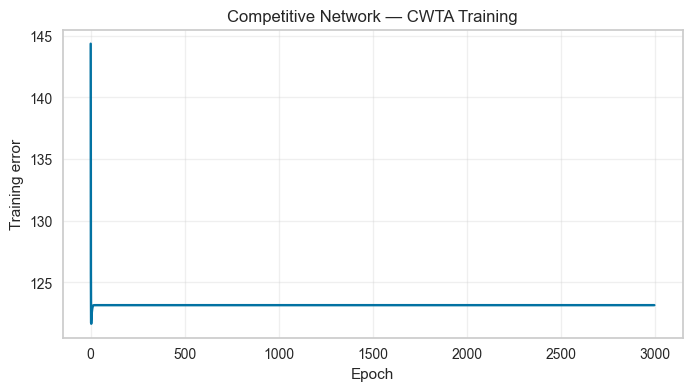

In [23]:
np.random.seed(RANDOM_STATE)

net_cwta = nl.net.newc(
    [[0.0, 1.0]] * X_unsupervised.shape[1],
    best_k,
)

error_cwta = nl.train.train_cwta(
    net_cwta,
    X_unsupervised,
    epochs=3000,
    show=100,
)

plt.figure(figsize=(8, 4))
plt.plot(error_cwta)
plt.xlabel("Epoch")
plt.ylabel("Training error")
plt.title("Competitive Network — CWTA Training")
plt.grid(alpha=0.3)
plt.show()


## 13. Cluster Visualization

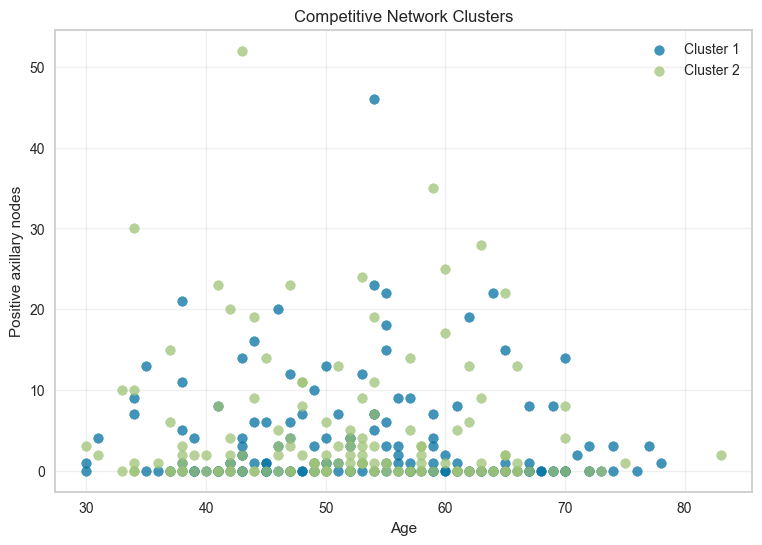

Total execution time: 17 min 39.21 sec


In [24]:
# Neurolab returns one competitive output per cluster.
cluster_output = net_cwta.sim(X_unsupervised)
cluster_labels = np.argmax(cluster_output, axis=1)

plt.figure(figsize=(9, 6))

for cluster_id in range(best_k):
    mask = cluster_labels == cluster_id
    plt.scatter(
        X[mask, 0],
        X[mask, 2],
        label=f"Cluster {cluster_id + 1}",
        alpha=0.75,
    )

plt.xlabel("Age")
plt.ylabel("Positive axillary nodes")
plt.title("Competitive Network Clusters")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

elapsed_time = time.time() - start_time

minutes = int(elapsed_time // 60)
seconds = elapsed_time % 60

print(f"Total execution time: {minutes} min {seconds:.2f} sec")


## 14. Conclusions

This project demonstrates a complete introductory neural-network workflow on Haberman's Survival Dataset.

The most important practical observations are:

- Input preprocessing and correct separation of training/test data are essential.
- Network architecture and training parameters can affect convergence and classification accuracy.
- Results should be compared using independent experiments rather than repeatedly training the same network.
- Different train/test ratios change both the amount of information available for training and the reliability of the test estimate.
- Unsupervised competitive learning provides a different view of the data because it forms groups without using the survival-status class during training.

The implementation intentionally remains close to the scope of the original 2022 university project rather than converting it into a modern deep-learning project.
